## Settings

In [2]:
import os
import sys
import json
import time
import wave
import random
import logging
import urllib.request
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass

import numpy as np


WORK         = Path("/workspace")
SETUP        = WORK / "AMI-diarization-setup"
AUDIO_ROOT   = SETUP / "pyannote" / "amicorpus"        # where database.yml looks for both headset and far-field audio
WAREHOUSE    = WORK / "warehouse" / "ami.duckdb"
BASELINE_RUN = WORK / "results" / "pyannote21_baseline" / "test" / "20261106_085354"   # Notebook 02


# 1. Right environment?

print("Python:", sys.version.split()[0], "|", sys.executable)
if "envs/pyannote21" not in sys.executable:
    raise RuntimeError("Wrong kernel! Top-right: choose 'Python (pyannote 2.1)'.")
os.environ["PYANNOTE_DATABASE_CONFIG"] = str(SETUP / "pyannote" / "database.yml")


# 2. Data and scoring (same rules as Notebook 02)

TRAIN_PROTOCOL   = "AMI-SDM.SpeakerDiarization.only_words"   # far-field: train / dev / test
HEADSET_PROTOCOL = "AMI.SpeakerDiarization.only_words"
SDM_CHANNEL      = "Array1-01"
AMI_MIRROR       = "https://groups.inf.ed.ac.uk/ami/AMICorpusMirror/amicorpus"
COLLAR, SKIP_OVERLAP = 0.0, False
PUBLISHED = {"farfield_pretrained_%": 27.1, "farfield_adapted_%": 22.2,   # [1], as cited in Workbook 1
             "headset_pretrained_%": 18.91}


# 3. Training (fixed before the first run)

PRETRAINED_SEGMENTATION = "pyannote/segmentation@2022.07"
PIPELINE_NAME           = "pyannote/speaker-diarization@2.1"
TRAIN_SEEDS   = [42]          # add 43, 44 if GPU time allows; the presentation asks for error bars over seeds
MAX_EPOCHS    = 20
PATIENCE      = 5             # early stopping on dev validation loss
BATCH_SIZE    = 32
NUM_WORKERS   = min(8, os.cpu_count() or 4)
LEARNING_RATE = 1e-4          # small: we adapt a trained model, we do not train from scratch


# 4. Hyperparameter search on dev

SEARCH_ITERATIONS = {"segmentation": 8, "clustering": 15}


# 5. Run ID, output folder, token

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
RESUME_RUN_ID = "20261106_182403"    # None = start a new run
if RESUME_RUN_ID:
    RUN_ID = RESUME_RUN_ID
OUT = WORK / "results" / "model1_finetuned_segmentation" / RUN_ID
for sub in ["checkpoints", "figures", "rttm"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

HF_TOKEN = os.environ.get("HF_TOKEN") or getpass("Paste your Hugging Face token: ")
os.environ["HF_TOKEN"] = HF_TOKEN

import torch
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE"
if GPU_NAME == "NOT AVAILABLE":
    raise RuntimeError("No GPU - fine-tuning needs a GPU.")

compute_log = json.loads((OUT / "compute_log.json").read_text()) if (OUT / "compute_log.json").exists() else []

def log_compute(step, seconds, note=""):
    compute_log.append({"step": step, "minutes": round(seconds / 60, 1), "gpu": GPU_NAME, "note": note})
    (OUT / "compute_log.json").write_text(json.dumps(compute_log, indent=2))



def trained_checkpoint(seed):
    """Best checkpoint of a finished training, read from disk (works after a kernel restart)."""
    done_file = OUT / "checkpoints" / f"seed_{seed}" / "best.txt"
    assert done_file.exists(), f"Seed {seed} is not trained yet in run {RUN_ID}: run the fine-tuning cell first"
    return done_file.read_text().strip()
    
print("GPU:", GPU_NAME, "| run:", RUN_ID, "| results go to:", OUT)

Python: 3.9.23 | /workspace/envs/pyannote21/bin/python
GPU: NVIDIA GeForce RTX 4090 | run: 20261106_182403 | results go to: /workspace/results/model1_finetuned_segmentation/20261106_182403


In [3]:
import torch

_original_stft = torch.stft

def _stft_on_cpu(input, *args, **kwargs):
    """Run the FFT on the CPU: the CUDA 11.7 cuFFT in this PyTorch fails on RTX 40-series GPUs.
    The result goes back to the original device, so the rest of the pipeline stays on the GPU."""
    if not input.is_cuda:
        return _original_stft(input, *args, **kwargs)
    to_cpu = lambda v: v.cpu() if torch.is_tensor(v) else v
    result = _original_stft(input.cpu(), *[to_cpu(a) for a in args], **{k: to_cpu(v) for k, v in kwargs.items()})
    return result.to(input.device)

torch.stft = _stft_on_cpu

# check that the patched version works on this GPU
x = torch.randn(1, 16000, device="cuda")
window = torch.hann_window(400, device="cuda")
out = torch.stft(x, 400, 160, 400, window, True, "constant", False, True, return_complex=True)
print("patched torch.stft works:", tuple(out.shape), out.device)


patched torch.stft works: (1, 201, 101) cuda:0


## Download the far-field audio (train, dev, test)
About 170 files, 10 GB, into the folder `database.yml` expects. Complete files are skipped. Each file is checked to be 16 kHz, mono, 16-bit.

In [4]:
import threading
from concurrent.futures import ThreadPoolExecutor

BLOCKED = threading.Event()          # set when the server answers 403, so we stop asking it


def sdm_path(meeting):
    return AUDIO_ROOT / meeting / "audio" / f"{meeting}.{SDM_CHANNEL}.wav"


def download(url, destination, retries=5):

    if destination.exists():
        return "skipped"
    if BLOCKED.is_set():
        return "FAILED"
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + ".part")
    for attempt in range(1, retries + 1):
        try:
            with urllib.request.urlopen(url, timeout=60) as response, open(temporary, "wb") as out:
                expected = int(response.headers.get("Content-Length", 0))
                while chunk := response.read(1 << 20):
                    out.write(chunk)
            if expected and temporary.stat().st_size != expected:
                raise IOError(f"size {temporary.stat().st_size} != {expected}")
            temporary.replace(destination)
            time.sleep(2)                       # short pause between files
            return "downloaded"
        except Exception as error:
            logging.warning(f"{destination.name}: attempt {attempt} failed: {error}")
            if "403" in str(error):
                BLOCKED.set()                   # blocked: stop all further requests
                return "FAILED"
            time.sleep(30 * attempt)
    return "FAILED"


splits = {s: (SETUP / "lists" / f"{s}.meetings.txt").read_text().split() for s in ["train", "dev", "test"]}
all_meetings = splits["test"] + splits["dev"] + splits["train"]

start = time.time()
with ThreadPoolExecutor(max_workers=1) as pool:          # 1 at a time, to be polite to the AMI server
    statuses = dict(zip(all_meetings, pool.map(
        lambda m: download(f"{AMI_MIRROR}/{m}/audio/{m}.{SDM_CHANNEL}.wav", sdm_path(m)), all_meetings)))

counts = {s: list(statuses.values()).count(s) for s in ["downloaded", "skipped", "FAILED"]}
print(counts, f"| {time.time() - start:.0f} s")
failed = [m for m, s in statuses.items() if s == "FAILED"]
if BLOCKED.is_set():
    raise RuntimeError(f"The AMI server answered 403 (blocked for now). {len(failed)} files are still missing. "
                       "Wait 30-60 minutes, then run this cell again: files already downloaded are skipped.")
assert not failed, f"{len(failed)} downloads failed - run this cell again: {failed[:10]}"

bad_format = []
for m in all_meetings:
    with wave.open(str(sdm_path(m)), "rb") as w:
        if (w.getframerate(), w.getnchannels(), w.getsampwidth()) != (16000, 1, 2):
            bad_format.append(m)
assert not bad_format, f"Not 16 kHz mono 16-bit: {bad_format}"
print(f"all {len(all_meetings)} far-field files OK")


{'downloaded': 0, 'skipped': 168, 'FAILED': 0} | 1 s
all 168 far-field files OK


## Load the data, the pretrained model and the baseline pipeline

In [5]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import pytorch_lightning as pl
import huggingface_hub.constants
import huggingface_hub.file_download
from pyannote.audio import Model, Pipeline
from pyannote.audio.tasks import Segmentation
from pyannote.audio.pipelines import SpeakerDiarization
from pyannote.database import FileFinder, get_protocol
from pyannote.database.custom import add_custom_protocols
from pyannote.database.util import load_rttm
from pyannote.core import Annotation
from pyannote.metrics.diarization import DiarizationErrorRate

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*torchaudio.info.*")
warnings.filterwarnings("ignore", message=".*precomputed key.*")
huggingface_hub.constants.HF_HUB_ENABLE_HF_TRANSFER = False
huggingface_hub.file_download.HF_HUB_ENABLE_HF_TRANSFER = False
add_custom_protocols()


# 1. Protocols: far-field for training and scoring, headset for scoring

farfield = get_protocol(TRAIN_PROTOCOL, preprocessors={"audio": FileFinder()})
headset  = get_protocol(HEADSET_PROTOCOL, preprocessors={"audio": FileFinder()})
dev_files  = list(farfield.development())
test_sdm   = list(farfield.test())
test_hs    = list(headset.test())
n_train = len(list(farfield.train()))
expected_train = len((SETUP / "lists" / "train.meetings.txt").read_text().split())
assert (n_train, len(dev_files), len(test_sdm)) == (expected_train, 18, 16), (n_train, len(dev_files), len(test_sdm))
if expected_train != 136:
    print(f"NOTE: training on {expected_train} of 136 train meetings (the others have no far-field audio on the AMI server); record this in the report.")



# 2. The baseline pipeline and its settings (the starting point)

baseline = Pipeline.from_pretrained(PIPELINE_NAME, use_auth_token=HF_TOKEN)
baseline_params = baseline.parameters(instantiated=True)
assert baseline.der_variant == {"collar": COLLAR, "skip_overlap": SKIP_OVERLAP}


versions = {"pyannote.audio": __import__("pyannote.audio").audio.__version__,
            "pytorch_lightning": pl.__version__, "torch": torch.__version__, "gpu": GPU_NAME}
(OUT / "run_info.json").write_text(json.dumps({
    "run_id": RUN_ID, "model": "M1 fine-tuned segmentation (pyannote 2.1)", "train_protocol": TRAIN_PROTOCOL,
    "pretrained_segmentation": PRETRAINED_SEGMENTATION, "pipeline": PIPELINE_NAME, "seeds": TRAIN_SEEDS,
    "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
    "search_iterations": SEARCH_ITERATIONS, "baseline_params": baseline_params, "versions": versions,
}, indent=2, default=float))
print(f"train {n_train} | dev {len(dev_files)} | test {len(test_sdm)} meetings | versions {versions}")

torchvision is not available - cannot save figures


NOTE: training on 134 of 136 train meetings (the others have no far-field audio on the AMI server); record this in the report.


/workspace/envs/pyannote21/lib/python3.9/site-packages/pyannote/audio/core/model.py:426: UserWarning: Model was trained with pyannote.audio 0.0.1, yours is 2.1.1. Bad things will probably happen unless you update pyannote.audio to 0.x.
  warnings.warn(


train 134 | dev 18 | test 16 meetings | versions {'pyannote.audio': '2.1.1', 'pytorch_lightning': '1.6.5.post0', 'torch': '1.13.1+cu117', 'gpu': 'NVIDIA GeForce RTX 4090'}


## Scoring helper
Runs a pipeline on a list of meetings (or loads its saved answers) and scores DER, overlap DER and the DER parts exactly like Notebook 02.

In [6]:
def run_and_score(pipeline, files, rttm_dir, label):

    rttm_dir.mkdir(parents=True, exist_ok=True)
    metric = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
    overlap_metric = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
    seconds = 0.0
    for file in files:
        rttm_file = rttm_dir / f"{file['uri']}.rttm"
        if rttm_file.exists():
            hypothesis = load_rttm(rttm_file).get(file["uri"], Annotation(uri=file["uri"]))
        else:
            start = time.perf_counter()
            hypothesis = pipeline({"uri": file["uri"], "audio": file["audio"]})
            seconds += time.perf_counter() - start
            with open(rttm_file, "w") as out:
                hypothesis.write_rttm(out)
        metric(file["annotation"], hypothesis, uem=file["annotated"])
        overlap_metric(file["annotation"], hypothesis,
                       uem=file["annotation"].get_timeline().get_overlap().crop(file["annotated"]))
    total = metric.report(display=False).loc["TOTAL"]
    speech = total[("total", "")]
    result = {"system": label, "meetings": len(files), "DER_%": abs(metric) * 100,
              "missed_%": 100 * total[("missed detection", "")] / speech,
              "false_alarm_%": 100 * total[("false alarm", "")] / speech,
              "confusion_%": 100 * total[("confusion", "")] / speech,
              "DER_overlap_%": abs(overlap_metric) * 100}
    if seconds:
        log_compute(f"inference: {label}", seconds)
    print(f"{label:45s} DER {result['DER_%']:6.2f}% | overlap {result['DER_overlap_%']:6.2f}%")
    return result


results = []
results.append(run_and_score(baseline, test_sdm, OUT / "rttm" / "baseline_farfield_test", "baseline, far-field test"))

baseline, far-field test                      DER  26.43% | overlap  45.05%


## Fine-tune the segmentation model
Starts from the pretrained weights, trains on far-field **train** with binary cross-entropy, checks the **dev** loss after every epoch, keeps the best epoch and stops after `PATIENCE` epochs without improvement. Every logged value goes to `metrics.csv` (learning curves).

In [7]:
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger


class CSVLoggerWithFigures(CSVLogger):
    """CSVLogger that also accepts figures.

    pyannote.audio 2.1.1 plots validation samples at epochs 1, 2, 4, 8, 16 through a TensorBoard-only call
    (logger.experiment.add_figure). With a plain CSVLogger that call raises AttributeError and stops the training.
    Here the plots are saved as PNG files next to the metrics instead.
    """

    @property
    def experiment(self):
        experiment = super().experiment
        if not hasattr(experiment, "add_figure"):
            figure_dir = Path(experiment.log_dir) / "validation_samples"

            def add_figure(tag, figure, global_step=None, *args, **kwargs):
                figure_dir.mkdir(parents=True, exist_ok=True)
                figure.savefig(figure_dir / f"{tag.replace('/', '_')}_epoch{global_step}.png", dpi=100)

            experiment.add_figure = add_figure
        return experiment


trained = {}           # seed -> path of the best checkpoint

for seed in TRAIN_SEEDS:
    seed_dir = OUT / "checkpoints" / f"seed_{seed}"
    done_file = seed_dir / "best.txt"
    if done_file.exists():
        trained[seed] = done_file.read_text().strip()
        print(f"seed {seed}: already trained -> {trained[seed]}")
        continue

    pl.seed_everything(seed, workers=True)
    model = Model.from_pretrained(PRETRAINED_SEGMENTATION, use_auth_token=HF_TOKEN)
    task = Segmentation(farfield, duration=model.specifications.duration,
                        max_num_speakers=len(model.specifications.classes),
                        batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, loss="bce", vad_loss="bce")
    model.task = task
    model.setup(stage="fit")

    def configure_optimizers():               # small learning rate: adapt, do not overwrite
        return torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    model.configure_optimizers = configure_optimizers

    monitor, direction = task.val_monitor
    checkpoint = ModelCheckpoint(dirpath=seed_dir, monitor=monitor, mode=direction, save_top_k=1,
                                 every_n_epochs=1, filename="{epoch}", save_weights_only=False)
    early_stop = EarlyStopping(monitor=monitor, mode=direction, patience=PATIENCE, min_delta=0.0)
    trainer = pl.Trainer(accelerator="gpu", devices=1, max_epochs=MAX_EPOCHS, gradient_clip_val=0.5,
                         callbacks=[checkpoint, early_stop], logger=CSVLoggerWithFigures(str(seed_dir), name="logs"),
                         deterministic=False, enable_progress_bar=True)

    start = time.perf_counter()
    trainer.fit(model)
    log_compute(f"training seed {seed}", time.perf_counter() - start,
                f"{trainer.current_epoch} epochs, monitor {monitor}, best {float(checkpoint.best_model_score):.4f}")

    trained[seed] = checkpoint.best_model_path
    done_file.write_text(trained[seed])
    print(f"seed {seed}: best {monitor} = {float(checkpoint.best_model_score):.4f} at {trained[seed]}")


seed 42: already trained -> /workspace/results/model1_finetuned_segmentation/20261106_182403/checkpoints/seed_42/epoch=12.ckpt


## Learning curves
Training and validation values per epoch, read from the training logs. The dashed line marks the epoch that was kept.

Logged values: ['OptimalDiarizationErrorRate', 'OptimalDiarizationErrorRateThreshold', 'OptimalSpeakerConfusionRate', 'OptimalMissedDetectionRate', 'OptimalFalseAlarmRate', 'BatchSize', 'TrainSegLoss', 'TrainVADLoss', 'TrainLoss']


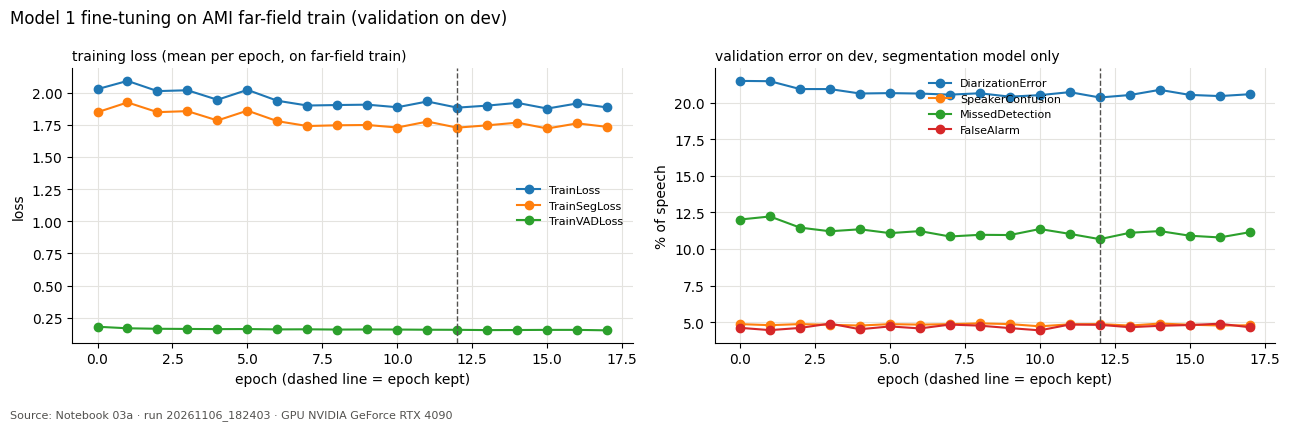

In [8]:
INK, NEUTRAL = "#0b0b0b", "#52514e"
PREFIX = "Segmentation-AMI-SDMSpeakerDiarizationonly_words-"

curves = []
for seed in TRAIN_SEEDS:
    logs = sorted((OUT / "checkpoints" / f"seed_{seed}" / "logs").glob("version_*/metrics.csv"))
    assert logs, f"No training log for seed {seed}"
    frame = pd.read_csv(logs[-1])
    per_epoch = frame.groupby("epoch").mean(numeric_only=True).reset_index()
    per_epoch["seed"] = seed
    curves.append(per_epoch)
curves = pd.concat(curves, ignore_index=True)
curves.columns = [c.replace(PREFIX, "") for c in curves.columns]

VALIDATION = ["OptimalDiarizationErrorRate", "OptimalSpeakerConfusionRate",
              "OptimalMissedDetectionRate", "OptimalFalseAlarmRate"]
for column in VALIDATION:                                  # rates are logged as fractions: show them in %
    if column in curves.columns:
        curves[column] = 100 * curves[column]
curves.to_csv(OUT / "learning_curves.csv", index=False)
print("Logged values:", [c for c in curves.columns if c not in ("epoch", "step", "seed")])

PANELS = {"training loss (mean per epoch, on far-field train)": ("loss", ["TrainLoss", "TrainSegLoss", "TrainVADLoss"]),
          "validation error on dev, segmentation model only": ("% of speech", VALIDATION)}

fig, axes = plt.subplots(1, len(PANELS), figsize=(6.5 * len(PANELS), 4), squeeze=False)
for ax, (title, (ylabel, columns)) in zip(axes[0], PANELS.items()):
    for column in columns:
        if column not in curves.columns:
            continue
        for seed, part in curves.groupby("seed"):
            part = part.dropna(subset=[column])
            label = column.replace("Optimal", "").replace("Rate", "") + ("" if len(TRAIN_SEEDS) == 1 else f" (seed {seed})")
            ax.plot(part["epoch"], part[column], marker="o", label=label)
    for seed in TRAIN_SEEDS:
        stem = Path(trained_checkpoint(seed)).stem
        if "=" in stem:
            ax.axvline(int(stem.split("=")[-1]), color=NEUTRAL, linestyle="--", linewidth=1)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("epoch (dashed line = epoch kept)")
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e4e3df", linewidth=0.8)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Model 1 fine-tuning on AMI far-field train (validation on dev)", x=0.01, ha="left")
fig.text(0.01, -0.04, f"Source: Notebook 03a · run {RUN_ID} · GPU {GPU_NAME}", fontsize=8, color=NEUTRAL)
plt.tight_layout()
plt.savefig(OUT / "figures" / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


## Hyperparameter search on dev
The fine-tuned segmentation model goes into the baseline pipeline (same speaker embedding and clustering). Then, on **dev** only:
1. search the **segmentation threshold** with the clustering settings frozen,
2. search the **clustering threshold** with the new segmentation threshold frozen.

Every trial is saved with its dev DER, so the presentation can show what was searched.

In [9]:
from pyannote.pipeline import Optimizer

SEED = TRAIN_SEEDS[0]
finetuned_model = Model.from_pretrained(trained_checkpoint(SEED))
search_file = OUT / "search_trials.csv"
params_file = OUT / "model1_pipeline_params.json"


def build_pipeline(segmentation_model, params):
    pipeline = SpeakerDiarization(segmentation=segmentation_model,
                                  embedding=baseline.embedding,
                                  embedding_exclude_overlap=baseline.embedding_exclude_overlap,
                                  clustering=baseline.klustering)
    pipeline.instantiate(params)
    return pipeline          # pyannote.audio 2.1.1 puts both models on the GPU by itself


if params_file.exists():
    best_params = json.loads(params_file.read_text())
    trials = pd.read_csv(search_file)
    print("Search already done:", best_params)
else:
    trials = []
    params = json.loads(json.dumps(baseline_params, default=float))

    # Every trial re-extracts speaker embeddings (about 26 min on all 18 dev meetings), so the thresholds are
    # tuned on a fixed subset: every third dev meeting (6 of 18, same rule for every run).
    search_files = dev_files[::3]
    (OUT / "search_dev_meetings.json").write_text(json.dumps([f["uri"] for f in search_files]))
    print("Search uses", len(search_files), "of", len(dev_files), "dev meetings:", [f["uri"] for f in search_files])


    def run_search(step, free_name, iterations, frozen, warm_start):
        """Tune ONE hyperparameter on dev. Every trial is recorded with its own dev DER (read from the study)."""

        pipeline = build_pipeline(finetuned_model, params)
        pipeline.freeze(frozen)
        optimizer = Optimizer(pipeline)
        start = time.perf_counter()
        for i, best_so_far in enumerate(optimizer.tune_iter(search_files, warm_start=warm_start, show_progress=False)):
            print(f"{step} trial {i + 1}/{iterations} done | best so far: dev DER {100 * best_so_far['loss']:.2f}% "
                  f"| {(time.perf_counter() - start) / 60:.1f} min")
            if i + 1 >= iterations:
                break
        frame = optimizer.study_.trials_dataframe()
        frame = frame[frame["state"] == "COMPLETE"]
        column = [c for c in frame.columns if c.startswith("params_")][0]        # the one parameter that was searched
        for _, row in frame.iterrows():
            trials.append({"step": step, "trial": int(row["number"]), "dev_DER_%": 100 * float(row["value"]),
                           free_name: float(row[column])})
        log_compute(f"search: {step}", time.perf_counter() - start, f"{len(frame)} trials on dev")
        return optimizer


    # Step 1: segmentation threshold (min_duration_off and clustering stay at the baseline values)
    optimizer = run_search("segmentation", "segmentation_threshold", SEARCH_ITERATIONS["segmentation"],
                           {"segmentation": {"min_duration_off": params["segmentation"]["min_duration_off"]},
                            "clustering": params["clustering"]},
                           {"segmentation": {"threshold": params["segmentation"]["threshold"]}})   # trial 1 = the baseline's value
    params["segmentation"]["threshold"] = optimizer.best_params["segmentation"]["threshold"]

    # Step 2: clustering threshold (segmentation now frozen at the best value)
    optimizer = run_search("clustering", "clustering_threshold", SEARCH_ITERATIONS["clustering"],
                           {"segmentation": params["segmentation"],
                            "clustering": {k: v for k, v in params["clustering"].items() if k != "threshold"}},
                           {"clustering": {"threshold": params["clustering"]["threshold"]}})       # trial 1 = the baseline's value
    params["clustering"]["threshold"] = optimizer.best_params["clustering"]["threshold"]

    best_params = params
    trials = pd.DataFrame(trials)
    trials.to_csv(search_file, index=False)
    params_file.write_text(json.dumps(best_params, indent=2, default=float))

print("\nBaseline settings :", json.dumps(baseline_params, default=float))
print("Model 1 settings  :", json.dumps(best_params, default=float))


Search already done: {'segmentation': {'min_duration_off': 0.5817029604921046, 'threshold': 0.5583875862131683}, 'clustering': {'method': 'centroid', 'min_cluster_size': 15, 'threshold': 0.6884370254551151}}

Baseline settings : {"segmentation": {"min_duration_off": 0.5817029604921046, "threshold": 0.4442333667381752}, "clustering": {"method": "centroid", "min_cluster_size": 15, "threshold": 0.7153814381597874}}
Model 1 settings  : {"segmentation": {"min_duration_off": 0.5817029604921046, "threshold": 0.5583875862131683}, "clustering": {"method": "centroid", "min_cluster_size": 15, "threshold": 0.6884370254551151}}


In [10]:
from pyannote.pipeline import Optimizer

SEED = TRAIN_SEEDS[0]
finetuned_model = Model.from_pretrained(trained[SEED])
search_file = OUT / "search_trials.csv"
params_file = OUT / "model1_pipeline_params.json"


def build_pipeline(segmentation_model, params):
    pipeline = SpeakerDiarization(segmentation=segmentation_model,
                                  embedding=baseline.embedding,
                                  embedding_exclude_overlap=baseline.embedding_exclude_overlap,
                                  clustering=baseline.klustering)
    pipeline.instantiate(params)
    return pipeline          # pyannote.audio 2.1.1 puts both models on the GPU by itself


if params_file.exists():
    best_params = json.loads(params_file.read_text())
    trials = pd.read_csv(search_file)
    print("Search already done:", best_params)
else:
    trials = []
    params = json.loads(json.dumps(baseline_params, default=float))


    def run_search(step, free_name, iterations, frozen):
        """Tune ONE hyperparameter on dev. Every trial is recorded with its own dev DER (read from the study)."""

        pipeline = build_pipeline(finetuned_model, params)
        pipeline.freeze(frozen)
        optimizer = Optimizer(pipeline)
        start = time.perf_counter()
        for i, best_so_far in enumerate(optimizer.tune_iter(dev_files, show_progress=False)):
            print(f"{step} trial {i + 1}/{iterations} done | best so far: dev DER {100 * best_so_far['loss']:.2f}% "
                  f"| {(time.perf_counter() - start) / 60:.1f} min")
            if i + 1 >= iterations:
                break
        frame = optimizer.study_.trials_dataframe()
        frame = frame[frame["state"] == "COMPLETE"]
        column = [c for c in frame.columns if c.startswith("params_")][0]        # the one parameter that was searched
        for _, row in frame.iterrows():
            trials.append({"step": step, "trial": int(row["number"]), "dev_DER_%": 100 * float(row["value"]),
                           free_name: float(row[column])})
        log_compute(f"search: {step}", time.perf_counter() - start, f"{len(frame)} trials on dev")
        return optimizer


    # Step 1: segmentation threshold (min_duration_off and clustering stay at the baseline values)
    optimizer = run_search("segmentation", "segmentation_threshold", SEARCH_ITERATIONS["segmentation"],
                           {"segmentation": {"min_duration_off": params["segmentation"]["min_duration_off"]},
                            "clustering": params["clustering"]})
    params["segmentation"]["threshold"] = optimizer.best_params["segmentation"]["threshold"]

    # Step 2: clustering threshold (segmentation now frozen at the best value)
    optimizer = run_search("clustering", "clustering_threshold", SEARCH_ITERATIONS["clustering"],
                           {"segmentation": params["segmentation"],
                            "clustering": {k: v for k, v in params["clustering"].items() if k != "threshold"}})
    params["clustering"]["threshold"] = optimizer.best_params["clustering"]["threshold"]

    best_params = params
    trials = pd.DataFrame(trials)
    trials.to_csv(search_file, index=False)
    params_file.write_text(json.dumps(best_params, indent=2, default=float))

print("\nBaseline settings :", json.dumps(baseline_params, default=float))
print("Model 1 settings  :", json.dumps(best_params, default=float))


Search already done: {'segmentation': {'min_duration_off': 0.5817029604921046, 'threshold': 0.5583875862131683}, 'clustering': {'method': 'centroid', 'min_cluster_size': 15, 'threshold': 0.6884370254551151}}

Baseline settings : {"segmentation": {"min_duration_off": 0.5817029604921046, "threshold": 0.4442333667381752}, "clustering": {"method": "centroid", "min_cluster_size": 15, "threshold": 0.7153814381597874}}
Model 1 settings  : {"segmentation": {"min_duration_off": 0.5817029604921046, "threshold": 0.5583875862131683}, "clustering": {"method": "centroid", "min_cluster_size": 15, "threshold": 0.6884370254551151}}


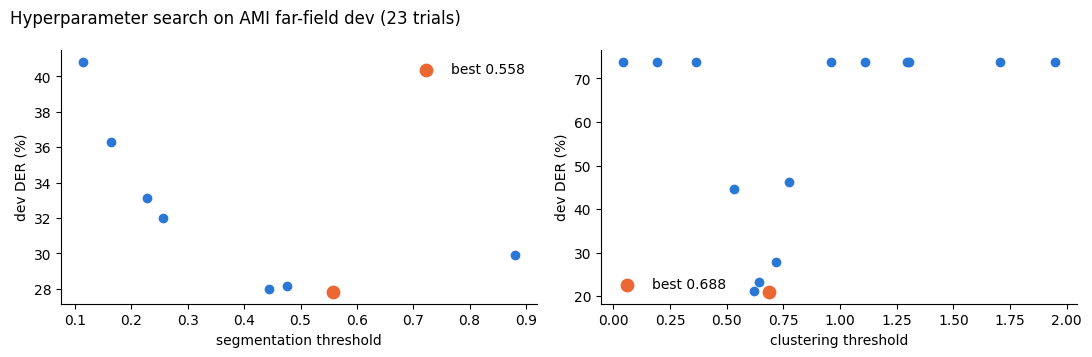

In [11]:
# Figure: every trial of the search (dev DER), best trial marked

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (step, column) in zip(axes, [("segmentation", "segmentation_threshold"), ("clustering", "clustering_threshold")]):
    part = trials[trials["step"] == step]
    ax.scatter(part[column], part["dev_DER_%"], color="#2a78d6")
    best = part.loc[part["dev_DER_%"].idxmin()]
    ax.scatter([best[column]], [best["dev_DER_%"]], color="#eb6834", s=80, label=f"best {best[column]:.3f}")
    ax.set_xlabel(column.replace("_", " "))
    ax.set_ylabel("dev DER (%)")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Hyperparameter search on AMI far-field dev ({len(trials)} trials)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(OUT / "figures" / "hyperparameter_search.png", dpi=150, bbox_inches="tight")
plt.show()

## Score Model 1 on the test split
Far-field test (the condition it was adapted for) and headset test (it must not lose the 19.11% baseline: Workbook 1, AI1).

In [12]:
model1 = build_pipeline(finetuned_model, best_params)
results.append(run_and_score(model1, test_sdm, OUT / "rttm" / "model1_farfield_test", "Model 1, far-field test"))
results.append(run_and_score(model1, test_hs, OUT / "rttm" / "model1_headset_test", "Model 1, headset test"))

baseline_headset = json.loads((BASELINE_RUN / "summary.json").read_text())
results.append({"system": "baseline, headset test (Notebook 02)", "meetings": 16,
                "DER_%": baseline_headset["der_%"], "missed_%": baseline_headset["miss_%"],
                "false_alarm_%": baseline_headset["fa_%"], "confusion_%": baseline_headset["conf_%"],
                "DER_overlap_%": baseline_headset["der_overlap_%"]})

table = pd.DataFrame(results).set_index("system").round(2)
table.to_csv(OUT / "test_results.csv")
print(table.to_string())

far_gain = table.loc["baseline, far-field test", "DER_%"] - table.loc["Model 1, far-field test", "DER_%"]
checks = {
    "far-field DER improves over the baseline": far_gain > 0,
    "headset DER <= 18.9% (AI1)": table.loc["Model 1, headset test", "DER_%"] <= 18.9,
    "headset overlap DER <= 33.82% (AI2)": table.loc["Model 1, headset test", "DER_overlap_%"] <= 33.82,
}
print(f"\nFar-field: baseline {table.loc['baseline, far-field test', 'DER_%']:.2f}% -> Model 1 "
      f"{table.loc['Model 1, far-field test', 'DER_%']:.2f}%  (paper: {PUBLISHED['farfield_pretrained_%']} -> {PUBLISHED['farfield_adapted_%']})")
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")

Model 1, far-field test                       DER  22.38% | overlap  45.65%
Model 1, headset test                         DER  19.48% | overlap  41.91%
                                      meetings  DER_%  missed_%  false_alarm_%  confusion_%  DER_overlap_%
system                                                                                                    
baseline, far-field test                    16  26.43     16.37           5.07         4.99          45.05
Model 1, far-field test                     16  22.38     12.60           4.12         5.66          45.65
Model 1, headset test                       16  19.48     11.30           4.05         4.12          41.91
baseline, headset test (Notebook 02)        16  19.52      8.65           5.27         5.60          38.97

Far-field: baseline 26.43% -> Model 1 22.38%  (paper: 27.1 -> 22.2)
PASS  far-field DER improves over the baseline
FAIL  headset DER <= 18.9% (AI1)
FAIL  headset overlap DER <= 33.82% (AI2)


## Save the model, the summary and the warehouse rows

In [13]:
import shutil
import duckdb

# 1. The model files the prototype and Notebook 03b use

model_dir = OUT / "model"
model_dir.mkdir(exist_ok=True)
shutil.copy(trained_checkpoint(SEED), model_dir / "segmentation.ckpt")
shutil.copy(params_file, model_dir / "pipeline_params.json")
(model_dir / "MODEL_CARD.md").write_text(
    f"# Model 1: fine-tuned segmentation for pyannote 2.1\n\n"
    f"* Base: {PRETRAINED_SEGMENTATION} in {PIPELINE_NAME}\n* Fine-tuned on: {TRAIN_PROTOCOL} train, early stopping on dev\n"
    f"* Seed {SEED}, run {RUN_ID}, GPU {GPU_NAME}\n* Pipeline settings: pipeline_params.json (searched on dev)\n"
    f"* Test DER: far-field {table.loc['Model 1, far-field test', 'DER_%']:.2f}%, headset {table.loc['Model 1, headset test', 'DER_%']:.2f}%\n")


# 2. Summary

gpu_minutes = sum(row["minutes"] for row in compute_log if "baseline" not in row["step"])
summary = {
    "run_id": RUN_ID, "model": "M1_finetuned_segmentation", "seeds": TRAIN_SEEDS, "gpu": GPU_NAME,
    "gpu_hours": round(gpu_minutes / 60, 2), "compute_log": compute_log,
    "baseline_params": baseline_params, "model1_params": best_params,
    "search_trials": int(len(trials)), "test": table.reset_index().to_dict(orient="records"),
    "checks": {k: bool(v) for k, v in checks.items()}, "published": PUBLISHED, "versions": versions,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
print(f"GPU time this run: {gpu_minutes / 60:.2f} h")
print(pd.DataFrame(compute_log).to_string(index=False))


# 3. Warehouse: one benchmark row per condition

rows = pd.DataFrame([{
    "model": "M1_finetuned_segmentation", "type": f"model 1 ({r['system']})", "split": "test", "run_id": RUN_ID,
    "meetings": r["meetings"], "der_%": r["DER_%"], "der_overlap_%": r["DER_overlap_%"],
    "runs": f"{len(TRAIN_SEEDS)} seed(s)", "gpu": GPU_NAME, "gpu_min": gpu_minutes,
} for r in results if r["system"].startswith("Model 1")])
with duckdb.connect(str(WAREHOUSE)) as con:
    con.register("incoming", rows)
    con.execute("CREATE TABLE IF NOT EXISTS model1_benchmark AS SELECT * FROM incoming WHERE 1 = 0")
    con.execute("DELETE FROM model1_benchmark WHERE run_id = ?", [RUN_ID])
    con.execute("INSERT INTO model1_benchmark BY NAME SELECT * FROM incoming")
    con.unregister("incoming")
print("\nSaved:", OUT, "\nModel files:", sorted(p.name for p in model_dir.iterdir()))
print("Next: Notebook 03b with RTTM_SOURCE =", OUT / "rttm" / "model1_headset_test")

GPU time this run: 2.80 h
                               step  minutes                     gpu                                                                                                         note
inference: baseline, far-field test     24.3 NVIDIA GeForce RTX 4090                                                                                                             
                   training seed 42     52.3 NVIDIA GeForce RTX 4090 18 epochs, monitor Segmentation-AMI-SDMSpeakerDiarizationonly_words-OptimalDiarizationErrorRate, best 0.2035
               search: segmentation     63.5 NVIDIA GeForce RTX 4090                                                                                              8 trials on dev
                 search: clustering      5.4 NVIDIA GeForce RTX 4090                                                                                             15 trials on dev
 inference: Model 1, far-field test     23.5 NVIDIA GeForce RTX 4090                

## Findings
Fill in after the run. Do not change targets or metrics.

* **Learning curves (epochs, best epoch, overfitting?):** …
* **Hyperparameters searched and chosen:** …
* **GPU time:** …
* **Far-field test: baseline vs Model 1 vs paper (27.1 → 22.2):** …
* **Headset test vs 18.9% and overlap vs 33.82%:** …